# v6 シミュレーション結果の確認

上から順に実行してください。`experiment_name`を変更すると別の実験を読み込めます。
使用するのは実験時に保存した`config_used.json`と4種類のCSVです。PyTorchやGPUは不要です。

- 条件・試行数、欠損値、重複、記録範囲の確認
- 条件別の平均個体数・利他行動・死亡年齢の比較
- 選択した条件の個体数・利他行動の時系列と遺伝子構成

**読み方**：集計CSVは全試行の結果ですが、時系列・遺伝子データは通常`run_id=0`だけです。
利他行動率は既存CSVの定義（正の移譲件数／ステップ終了時個体数）を使用します。
欠損した率や死亡年齢は、ゼロに置き換えません。

In [1]:
import json
from pathlib import Path
from decimal import Decimal
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ここを変更して読み込む実験を選びます。
experiment_name = "exp_v6_grid_search"

# プロジェクトルート／notebooksのどちらから起動しても読み込めます。
project_dir = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "configs").is_dir() and (p / "src").is_dir()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("プロジェクト内でノートブックを起動してください。")
experiment_dir = project_dir / "data" / experiment_name
required_files = ["config_used.json", "raw_data.csv", "summary_data.csv",
                  "time_series_data.csv", "genotype_time_series_data.csv"]
missing_files = [name for name in required_files if not (experiment_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"不足ファイル: {missing_files}\n実験結果: {experiment_dir}")

config = json.loads((experiment_dir / "config_used.json").read_text(encoding="utf-8"))
grid_keys = list(config.get("grid_parameters", {}))
raw_df = pd.read_csv(experiment_dir / "raw_data.csv")
summary_df = pd.read_csv(experiment_dir / "summary_data.csv")
time_series_df = pd.read_csv(experiment_dir / "time_series_data.csv")
# 先頭の0を維持し、8ビットの遺伝子として読み込みます。
genotype_df = pd.read_csv(experiment_dir / "genotype_time_series_data.csv", dtype={"genotype": "string"})
frames = {"raw": raw_df, "summary": summary_df,
          "time_series": time_series_df, "genotype": genotype_df}
required_columns = {
    "raw": ["run_id", "seed", "avg_population", "avg_altruism_count", "avg_altruism_rate", "avg_death_age"],
    "summary": ["num_runs", "avg_population", "std_population", "avg_altruism_count",
                "std_altruism_count", "avg_altruism_rate", "std_altruism_rate", "avg_death_age"],
    "time_series": ["run_id", "seed", "step", "population", "altruism_count", "altruism_rate"],
    "genotype": ["run_id", "seed", "step", "genotype", "population"],
}
for name, frame in frames.items():
    missing = set(grid_keys + required_columns[name]) - set(frame.columns)
    if missing:
        raise ValueError(f"{name}の不足列: {sorted(missing)}")
if not genotype_df["genotype"].str.fullmatch(r"[01]{8}").all():
    raise ValueError("genotype列には8桁の0/1が必要です。")

# CSVの行順に依存せず、全パラメータの組を1つの条件として識別します。
if grid_keys:
    conditions = pd.concat([raw_df[grid_keys], summary_df[grid_keys]]).drop_duplicates()
    conditions = conditions.sort_values(grid_keys).reset_index(drop=True)
    conditions.insert(0, "condition_id", np.arange(len(conditions)))
    for name, frame in frames.items():
        frames[name] = frame.merge(conditions, on=grid_keys, how="left", validate="many_to_one")
        if frames[name]["condition_id"].isna().any():
            raise ValueError(f"{name}に集計CSVと対応しない条件があります。")
else:
    conditions = pd.DataFrame({"condition_id": [0]})
    frames = {name: frame.assign(condition_id=0) for name, frame in frames.items()}
raw_df, summary_df, time_series_df, genotype_df = (frames[name] for name in frames)
print(f"実験結果: {experiment_dir}")
display(config)

実験結果: /mnt/nfs/hera/nishimura/2703-nishimura-bachelor-thesis/project/data/exp_v6_grid_search


{'experiment_name': 'exp_v6_grid_search',
 'agent_class': 'AgentV6',
 'field_class': 'FieldV6',
 'simulation': {'total_steps': 200000,
  'eval_start_step': 100001,
  'num_runs': 10,
  'base_seed': 42,
  'workers': 1,
  'device': 'cuda:0',
  'batch_size': 1200},
 'grid_parameters': {'initial_food_prob': [0.1, 0.2],
  'step_food_prob': [0.01, 0.02],
  'food_durability': [3, 5],
  'death_threshold': [-100, -80, -60, -40, -20, -5],
  'transfer_amount': [1, 3, 5, 7, 9]},
 'fixed_field_parameters': {'field_size': 10,
  'initial_agents': 20,
  'mutation_rate': 0.05,
  'energy_loss_per_step': 0.1,
  'reward_food': 1.0,
  'clone_threshold': 100.0}}

## 1. データの概要と確認

`condition_id`はこのノートブック内で付けた条件番号です。各番号のパラメータは`conditions`で確認できます。
設定と試行数が合わない場合や重複がある場合は、実験が完了しているかを確認してください。
死亡年齢の欠損は、評価期間内に死亡が観測されなかった場合などに発生します。

In [2]:
def expand_values(values):
    if isinstance(values, list):
        return values
    start, stop, step = (Decimal(str(values[key])) for key in ("start", "stop", "step"))
    if not all(value.is_finite() for value in (start, stop, step)) or step == 0:
        raise ValueError("範囲指定には有限値と0以外のstepが必要です。")
    result = []
    value = start
    while value < stop if step > 0 else value > stop:
        result.append(float(value))
        value += step
    return result

expected_values = [expand_values(config["grid_parameters"][key]) for key in grid_keys]
expected_conditions = int(np.prod([len(values) for values in expected_values])) if grid_keys else 1
expected_runs = config["simulation"].get("num_runs", 1)
print(f"条件数: {len(conditions)} / 設定上 {expected_conditions}")
print(f"試行数: {len(raw_df)} / 設定上 {expected_conditions * expected_runs}")
display(pd.DataFrame([
    {"データ": name, "行数": len(frame), "欠損セル数": int(frame.isna().sum().sum())}
    for name, frame in frames.items()
]))

coverage = conditions.merge(
    raw_df.groupby("condition_id")["run_id"].nunique().rename("recorded_runs"),
    on="condition_id", how="left",
)
coverage["recorded_runs"] = coverage["recorded_runs"].fillna(0).astype(int)
coverage["expected_runs"] = expected_runs
incomplete = coverage.loc[coverage["recorded_runs"] != expected_runs]
if not incomplete.empty:
    print("試行数が設定と異なる条件:")
    display(incomplete)
if grid_keys:
    expected_table = pd.DataFrame(product(*expected_values), columns=grid_keys).drop_duplicates()
    missing_conditions = expected_table.merge(conditions, on=grid_keys, how="left", indicator=True)
    missing_conditions = missing_conditions.loc[missing_conditions["_merge"] == "left_only", grid_keys]
    if not missing_conditions.empty:
        print("CSVにまだ存在しない条件:")
        display(missing_conditions)

for name, keys in {
    "raw": ["condition_id", "run_id"], "summary": ["condition_id"],
    "time_series": ["condition_id", "run_id", "step"],
    "genotype": ["condition_id", "run_id", "step", "genotype"],
}.items():
    count = int(frames[name].duplicated(keys).sum())
    print(f"{name}: 重複行 {count}")
if not time_series_df.empty:
    print("時系列のrun_id:", sorted(time_series_df["run_id"].unique().tolist()))
    print("記録step:", int(time_series_df["step"].min()), "〜", int(time_series_df["step"].max()))
display(conditions.head(20))

条件数: 240 / 設定上 240
試行数: 2400 / 設定上 2400


,データ,行数,欠損セル数
0,raw,2400,2
1,summary,240,0
2,time_series,48240,0
3,genotype,430095,0


raw: 重複行 0
summary: 重複行 0
time_series: 重複行 0
genotype: 重複行 0
時系列のrun_id: [0]
記録step: 1 〜 200000


,condition_id,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount
0,0,0.1,0.01,3,-100,1
1,1,0.1,0.01,3,-100,3
2,2,0.1,0.01,3,-100,5
3,3,0.1,0.01,3,-100,7
4,4,0.1,0.01,3,-100,9
5,5,0.1,0.01,3,-80,1
6,6,0.1,0.01,3,-80,3
7,7,0.1,0.01,3,-80,5
8,8,0.1,0.01,3,-80,7
9,9,0.1,0.01,3,-80,9


## 2. 条件別の集計

平均個体数・利他行動件数は評価期間における1ステップ当たりの値です。
`std_*`は試行平均の試行間標準偏差、`avg_within_run_std_*`は各試行内の標準偏差の平均です。
`avg_death_age`は、死亡が観測された試行の平均死亡年齢を試行ごとに等しく重み付けした値です。

In [3]:
summary_columns = ["condition_id", *grid_keys, "num_runs", "avg_population", "std_population",
                   "avg_altruism_count", "std_altruism_count", "avg_altruism_rate",
                   "std_altruism_rate", "avg_death_age"]
# 全条件の表は summary_df、試行別の表は raw_df に保持しています。
display(summary_df[summary_columns].sort_values(
    "avg_altruism_rate", ascending=False, na_position="last"
).head(20))

,condition_id,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount,num_runs,avg_population,std_population,avg_altruism_count,std_altruism_count,avg_altruism_rate,std_altruism_rate,avg_death_age
130,130,0.2,0.01,3,-60,1,10,29.682023,0.095796,0.009545,0.017201,0.000321,0.000577,61778.509227
80,80,0.1,0.02,3,-20,1,10,58.701120,0.225640,0.011148,0.011623,0.000190,0.000198,35233.906949
70,70,0.1,0.02,3,-60,1,10,59.662762,0.093355,0.011177,0.016798,0.000187,0.000281,70141.021889
55,55,0.1,0.01,5,-5,1,10,45.986302,0.836302,0.008464,0.005688,0.000183,0.000121,12358.725166
230,230,0.2,0.02,5,-20,1,10,98.054486,0.407578,0.017423,0.010880,0.000177,0.000110,38806.426135
170,170,0.2,0.01,5,-20,1,10,48.582657,0.293842,0.008593,0.004354,0.000177,0.000089,29861.104522
50,50,0.1,0.01,5,-20,1,10,48.611934,0.242666,0.008055,0.003057,0.000166,0.000063,30499.949564
115,115,0.1,0.02,5,-5,1,10,93.779341,1.012632,0.015588,0.013816,0.000165,0.000143,16540.023218
10,10,0.1,0.01,3,-60,1,10,29.660379,0.074242,0.004884,0.002901,0.000165,0.000097,57121.974184
175,175,0.2,0.01,5,-5,1,10,45.760323,0.600606,0.007554,0.004650,0.000164,0.000099,11498.167366


## 3. 条件を絞って比較するヒートマップ

既定では死亡閾値×移譲量を比較し、残りのパラメータは最初の条件の値に固定します。
`comparison_filters`を書き換えて、餌の発生確率・耐久度などを切り替えてください。
各マスは1条件の試行平均です。灰色は欠損・未記録です。

固定したパラメータ: {'initial_food_prob': np.float64(0.1), 'step_food_prob': np.float64(0.01), 'food_durability': np.float64(3.0)}


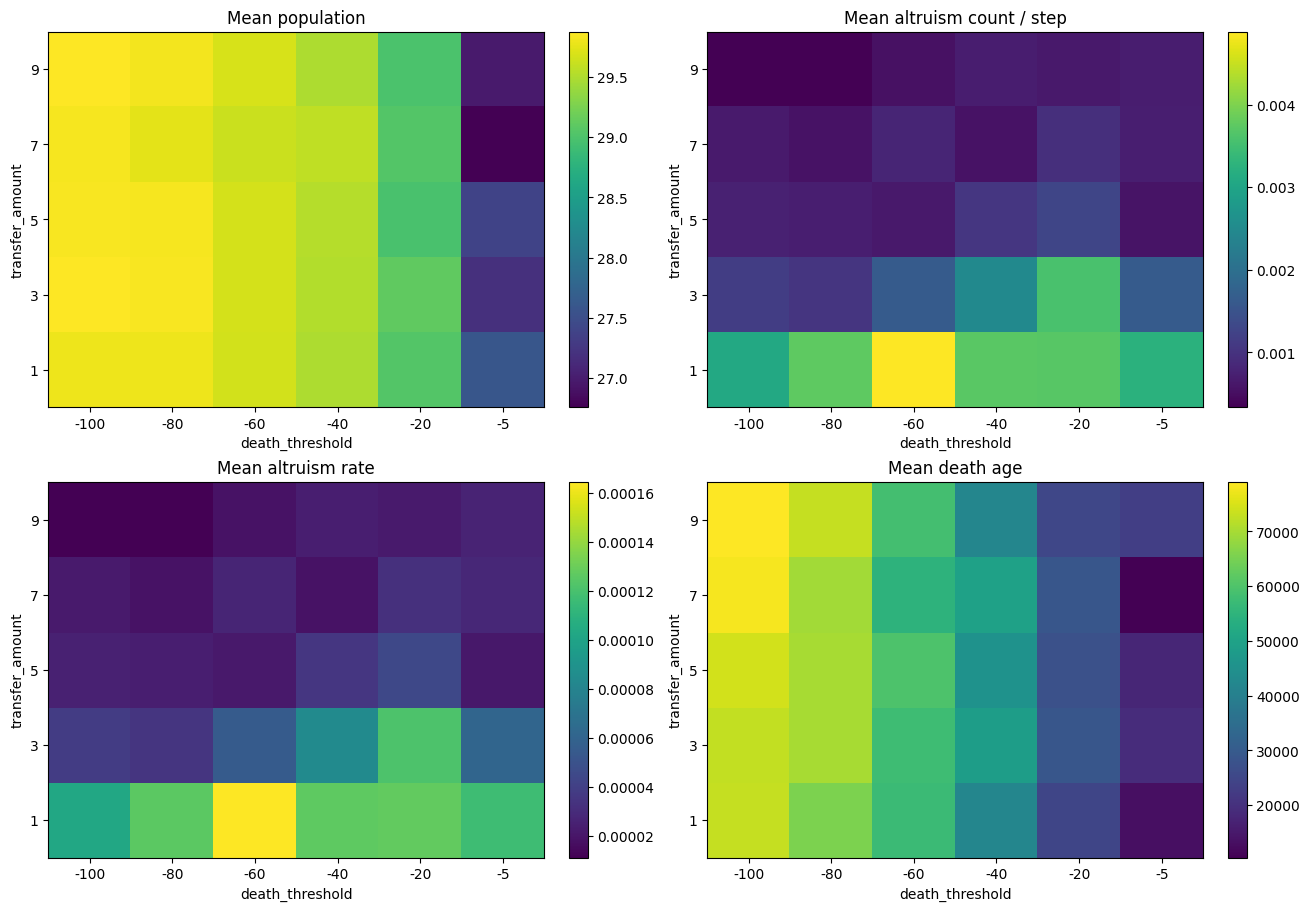

,condition_id,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount,num_runs,avg_population,std_population,avg_altruism_count,std_altruism_count,avg_altruism_rate,std_altruism_rate,avg_death_age
0,0,0.1,0.01,3,-100,1,10,29.795744,0.166974,0.003074,0.002051,0.000103,0.000069,73026.196243
5,5,0.1,0.01,3,-80,1,10,29.794470,0.106601,0.003747,0.001884,0.000126,0.000063,65466.312356
10,10,0.1,0.01,3,-60,1,10,29.660379,0.074242,0.004884,0.002901,0.000165,0.000097,57121.974184
15,15,0.1,0.01,3,-40,1,10,29.485276,0.088884,0.003722,0.001313,0.000126,0.000045,41976.411802
20,20,0.1,0.01,3,-20,1,10,29.040383,0.116000,0.003702,0.001297,0.000128,0.000045,24638.132580
25,25,0.1,0.01,3,-5,1,10,27.588019,0.754415,0.003232,0.001884,0.000117,0.000068,13114.052512
1,1,0.1,0.01,3,-100,3,10,29.868437,0.084352,0.001155,0.000750,0.000039,0.000025,72861.465948
6,6,0.1,0.01,3,-80,3,10,29.838313,0.125756,0.001042,0.000296,0.000035,0.000010,69960.701190
11,11,0.1,0.01,3,-60,3,10,29.672917,0.126504,0.001639,0.000677,0.000055,0.000023,57756.765998
16,16,0.1,0.01,3,-40,3,10,29.513975,0.142734,0.002495,0.002039,0.000085,0.000069,48596.507587


In [4]:
x_parameter = "death_threshold" if "death_threshold" in grid_keys else (grid_keys[0] if grid_keys else None)
y_parameter = "transfer_amount" if "transfer_amount" in grid_keys and x_parameter != "transfer_amount" else next(
    (key for key in grid_keys if key != x_parameter), None
)
comparison_filters = {
    key: conditions.iloc[0][key]
    for key in grid_keys if key not in (x_parameter, y_parameter) and not conditions.empty
}
# 例: comparison_filters.update(initial_food_prob=0.2, step_food_prob=0.02, food_durability=5)

def select_values(frame, filters):
    selected = frame
    for key, value in filters.items():
        if key not in grid_keys:
            raise ValueError(f"未知のパラメータ: {key}")
        selected = selected.loc[selected[key] == value]
    return selected

comparison_df = select_values(summary_df, comparison_filters)
print("固定したパラメータ:", comparison_filters)
if comparison_df.empty:
    print("該当する条件がありません。comparison_filtersを確認してください。")
else:
    plot_df = comparison_df.copy()
    x_col, y_col = x_parameter or "_x", y_parameter or "_y"
    if x_parameter is None:
        plot_df[x_col] = "All"
    if y_parameter is None:
        plot_df[y_col] = "All"
    metrics = [("avg_population", "Mean population"),
               ("avg_altruism_count", "Mean altruism count / step"),
               ("avg_altruism_rate", "Mean altruism rate"),
               ("avg_death_age", "Mean death age")]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("lightgray")
    for axis, (metric, title) in zip(axes.flat, metrics):
        table = plot_df.pivot(index=y_col, columns=x_col, values=metric).sort_index().sort_index(axis=1)
        heat = axis.imshow(np.ma.masked_invalid(table.to_numpy(dtype=float)),
                           origin="lower", aspect="auto", cmap=cmap)
        axis.set_xticks(np.arange(len(table.columns)), [str(value) for value in table.columns])
        axis.set_yticks(np.arange(len(table.index)), [str(value) for value in table.index])
        axis.set_xlabel(x_parameter or "Condition")
        axis.set_ylabel(y_parameter or "Condition")
        axis.set_title(title)
        fig.colorbar(heat, ax=axis)
    plt.show()
    display(comparison_df[summary_columns].sort_values([key for key in (y_parameter, x_parameter) if key]
                                                      or ["condition_id"]))

## 4. 1条件の試行別結果と時系列

下の`selected_condition_id`を`conditions`の番号に変更してください。時系列の既定試行は`run_id=0`です。
利他件数は記録区間の合計です（最初はstep 1、その後は2〜1000、1001〜2000、…）。
利他率はその区間の「件数の合計／個体数の合計」であり、ステップごとの率の単純平均ではありません。
背景の薄い色は集計に使用した評価期間を示します。

,condition_id,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount
0,0,0.1,0.01,3,-100,1


,run_id,seed,avg_population,std_population,avg_altruism_count,avg_altruism_rate,avg_death_age,std_death_age
0,0,42,29.80299,0.924741,0.00717,0.000241,60456.652174,62851.491893
1,1,43,29.80010,0.872002,0.00263,0.000088,73806.318182,63424.107488
2,2,44,29.65483,1.165058,0.00292,0.000098,81738.625000,50769.157233
3,3,45,29.59735,1.269992,0.00101,0.000034,72297.440000,63653.238117
4,4,46,29.91137,0.979849,0.00150,0.000050,66413.700000,47794.305379
5,5,47,29.85449,1.067140,0.00181,0.000061,58983.153846,57478.198292
6,6,48,30.01051,1.546164,0.00614,0.000205,68188.583333,53441.429200
7,7,49,30.00217,1.058167,0.00334,0.000111,88020.909091,64672.448797
8,8,50,29.50338,1.061847,0.00288,0.000098,77318.944444,62394.538886
9,9,51,29.82025,1.073318,0.00134,0.000045,83037.636364,50044.887632


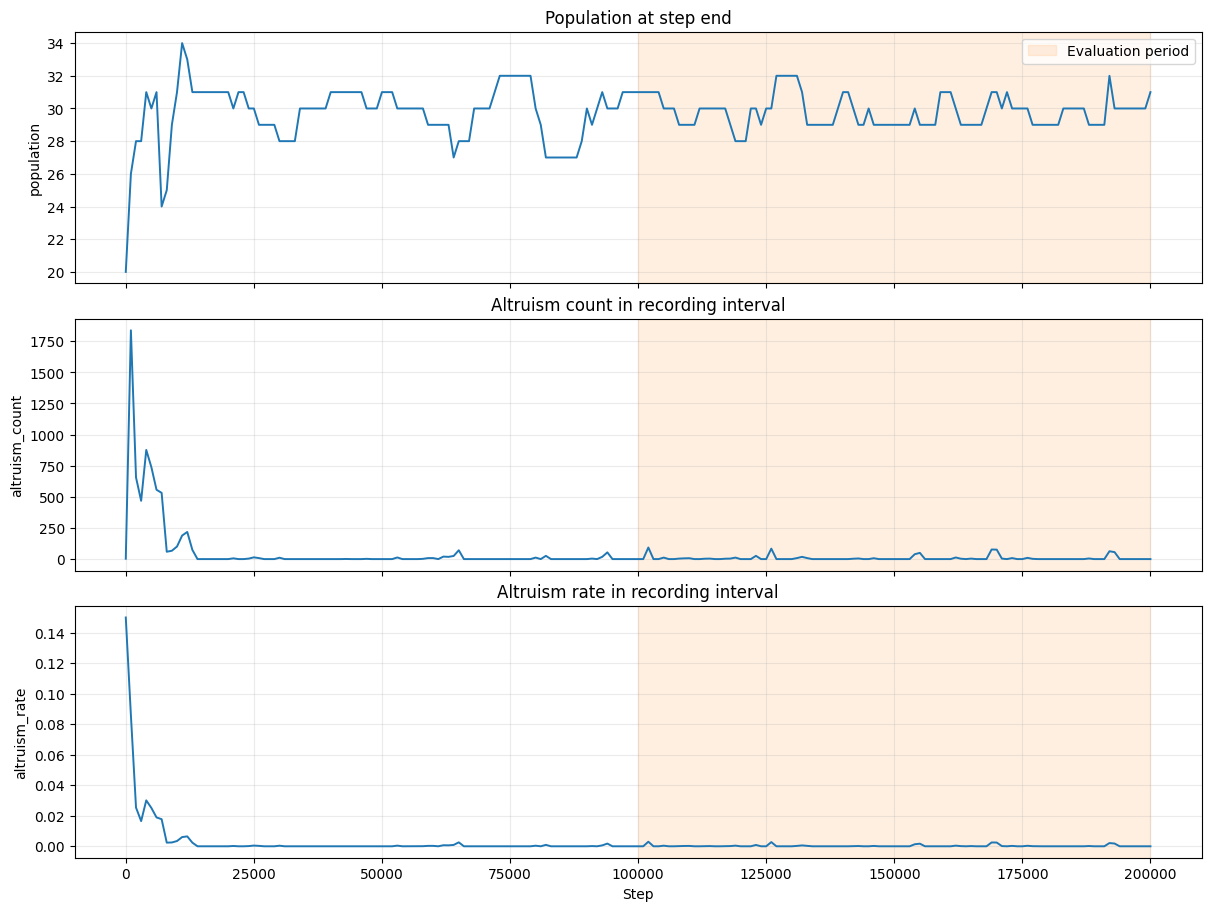

,initial_food_prob,step_food_prob,food_durability,death_threshold,transfer_amount,run_id,seed,step,population,altruism_count,altruism_rate,condition_id
22920,0.1,0.01,3,-100,1,0,42,191000,29,0,0.000000,0
23040,0.1,0.01,3,-100,1,0,42,192000,32,63,0.002111,0
23160,0.1,0.01,3,-100,1,0,42,193000,30,56,0.001801,0
23280,0.1,0.01,3,-100,1,0,42,194000,30,0,0.000000,0
23400,0.1,0.01,3,-100,1,0,42,195000,30,0,0.000000,0
23520,0.1,0.01,3,-100,1,0,42,196000,30,0,0.000000,0
23640,0.1,0.01,3,-100,1,0,42,197000,30,0,0.000000,0
23760,0.1,0.01,3,-100,1,0,42,198000,30,0,0.000000,0
23880,0.1,0.01,3,-100,1,0,42,199000,30,0,0.000000,0
24000,0.1,0.01,3,-100,1,0,42,200000,31,0,0.000000,0


In [5]:
selected_condition_id = int(conditions["condition_id"].iloc[0]) if not conditions.empty else 0
selected_run_id = 0
# 例: selected_condition_id = 12

selected_condition = conditions.loc[conditions["condition_id"] == selected_condition_id]
if selected_condition.empty:
    raise ValueError("conditionsに存在するcondition_idを指定してください。")
display(selected_condition)
selected_raw = raw_df.loc[raw_df["condition_id"] == selected_condition_id].sort_values("run_id")
display(selected_raw[["run_id", "seed", "avg_population", "std_population", "avg_altruism_count",
                      "avg_altruism_rate", "avg_death_age", "std_death_age"]])

selected_series = time_series_df.loc[
    (time_series_df["condition_id"] == selected_condition_id) &
    (time_series_df["run_id"] == selected_run_id)
].sort_values("step")
if selected_series.empty:
    print("この条件・試行の時系列はありません。通常はrun_id=0のみ記録されます。")
else:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
    for axis, metric, title in zip(axes,
            ["population", "altruism_count", "altruism_rate"],
            ["Population at step end", "Altruism count in recording interval", "Altruism rate in recording interval"]):
        axis.plot(selected_series["step"], selected_series[metric], linewidth=1.4)
        axis.axvspan(config["simulation"]["eval_start_step"], config["simulation"]["total_steps"],
                     color="tab:orange", alpha=.12, label="Evaluation period")
        axis.set_ylabel(metric)
        axis.set_title(title)
        axis.grid(alpha=.25)
    axes[0].legend()
    axes[-1].set_xlabel("Step")
    plt.show()
    display(selected_series.tail(10))

## 5. 遺伝子構成の推移

同じ条件・試行について、記録された個体数の合計が大きい上位の遺伝子型を表示します。
残りは`Other`にまとめ、分母には各記録時点の全遺伝子型の個体数を使用します。
この順位は記録時点の合計に基づくもので、全ステップの個体時間ではありません。
遺伝子型は先頭の0を含む8桁のビット列です。絶滅した記録時点の頻度は未定義なので空白にします。

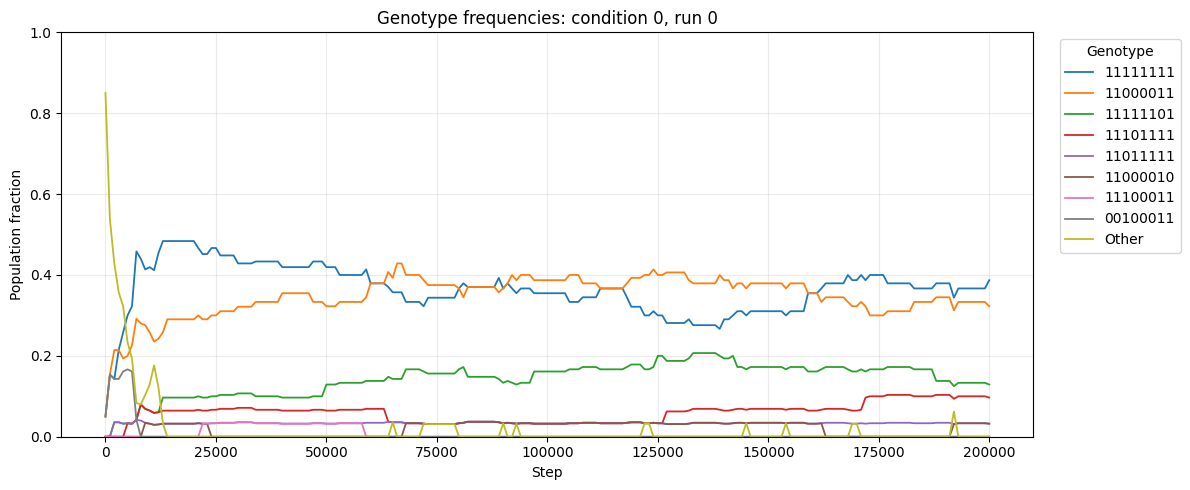

遺伝子データがある最後のstep: 200000（最終stepとは限りません）


,genotype,population,frequency
212732,11111111,12,0.387097
212728,11000011,10,0.322581
212731,11111101,4,0.129032
212730,11101111,3,0.096774
212727,11000010,1,0.032258
212729,11011111,1,0.032258


時系列と遺伝子個体数が一致しない記録: 0件


In [6]:
top_genotypes = 8
if type(top_genotypes) is not int or top_genotypes < 1:
    raise ValueError("top_genotypesは1以上の整数にしてください。")
selected_genotypes = genotype_df.loc[
    (genotype_df["condition_id"] == selected_condition_id) &
    (genotype_df["run_id"] == selected_run_id)
].sort_values(["step", "genotype"])

if selected_genotypes.empty:
    print("この条件・試行の遺伝子データはありません。初回記録までの絶滅でも空になります。")
else:
    genotype_counts = selected_genotypes.pivot(index="step", columns="genotype", values="population").fillna(0)
    # 絶滅後は遺伝子CSVに行がないため、時系列CSVの記録stepで補います。
    if not selected_series.empty:
        genotype_counts = genotype_counts.reindex(selected_series["step"], fill_value=0)
    genotype_counts = genotype_counts.sort_index()
    genotype_totals = genotype_counts.sum(axis=1)
    top_codes = genotype_counts.sum(axis=0).sort_values(ascending=False).head(top_genotypes).index.tolist()
    plot_counts = genotype_counts[top_codes].copy()
    if len(top_codes) < len(genotype_counts.columns):
        plot_counts["Other"] = genotype_totals - plot_counts.sum(axis=1)
    genotype_frequencies = plot_counts.div(genotype_totals.replace(0, np.nan), axis=0)
    axis = genotype_frequencies.plot(figsize=(12, 5), linewidth=1.3)
    axis.set(title=f"Genotype frequencies: condition {selected_condition_id}, run {selected_run_id}",
             xlabel="Step", ylabel="Population fraction", ylim=(0, 1))
    axis.grid(alpha=.25)
    axis.legend(title="Genotype", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    last_step = selected_genotypes["step"].max()
    print(f"遺伝子データがある最後のstep: {last_step}（最終stepとは限りません）")
    latest = selected_genotypes.loc[selected_genotypes["step"] == last_step, ["genotype", "population"]].copy()
    latest["frequency"] = latest["population"] / latest["population"].sum()
    display(latest.sort_values("population", ascending=False).head(20))

    if not selected_series.empty:
        check = selected_series[["step", "population"]].set_index("step").rename(columns={"population": "series_population"})
        check["genotype_population"] = genotype_totals.reindex(check.index, fill_value=0)
        mismatched = check.loc[check["series_population"] != check["genotype_population"]]
        print(f"時系列と遺伝子個体数が一致しない記録: {len(mismatched)}件")
        if not mismatched.empty:
            display(mismatched)